In [ ]:
# Cell 1: Imports, Setup, and Helper Functions
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
import optuna
from optuna.visualization import plot_pareto_front
import gc
from spatial_split import load_year_split

# 1. Directories and Global Constants
data_base_dir = Path('data/regionwise_yearwise_samples')
artifact_dir = Path('data/feature_selection_artifacts')
output_config_dir = Path('data/optuna_regional_gee_configs')
output_config_dir.mkdir(parents=True, exist_ok=True)

# TARGET_REGIONS = ['DES', 'IGP', 'WGR', 'ICR'] 
# TARGET_REGIONS = ['IGP', 'WGR', 'ICR'] 
TARGET_REGIONS = ['DES', 'IGP', 'WGR', 'ICR','NEI', 'PEN', 'HIM']
BENCHMARK_YEARS = [1990, 1995, 2000, 2002, 2006, 2013, 2019, 2024]

# 2. Class Remapping
old_codes = [5, 3, 4, 12, 11, 66, 19, 36, 9, 41, 24, 23, 75, 30, 25, 33, 76, 34, 61]
new_codes = [5, 3, 4, 12, 11, 66, 19, 14, 14, 14, 22, 22, 22, 22, 22, 33, 76, 34, 61]
class_remap_dict = dict(zip(old_codes, new_codes))

# 3. Reference Balancing Setup
ref_csv_path = Path('data/classwise_samples_reference_ratios.csv')
ref_df = pd.read_csv(ref_csv_path)
ref_df['old_code'] = old_codes
ref_df['new_code'] = new_codes
ref_region_cols = [c for c in ref_df.columns if c not in ['l2_code', 'l2_name', 'l1_parent', 'old_code', 'new_code']]
parent_ref_df = ref_df.groupby('new_code')[ref_region_cols].sum()

def get_balanced_indices(y_train_arr, target_n, ref_series, rng):
    classes = np.unique(y_train_arr)
    col_present = ref_series.reindex(classes).fillna(0.0)
    scaled = (np.sqrt(col_present) / sum(np.sqrt(col_present))) * target_n
    selected = []
    for cls in classes:
        cls_idx = np.where(y_train_arr == cls)[0]
        desired = int(np.round(scaled.get(cls, 0)))
        n_sample = min(len(cls_idx), max(3, desired))
        selected.extend(rng.choice(cls_idx, size=n_sample, replace=False))
    return np.array(selected)


🚀 STARTING PIPELINE FOR REGION: DES

[DES] Loaded 104 ranked features, 35 uncorrelated features.
[DES] Loading and caching benchmark years...
1990  Train: 79.92%  Val: 15.03%  Test: 5.05%
1995  Train: 79.91%  Val: 15.00%  Test: 5.09%
2000  Train: 79.88%  Val: 15.06%  Test: 5.06%
2002  Train: 79.95%  Val: 15.00%  Test: 5.05%
2006  Train: 79.89%  Val: 15.05%  Test: 5.06%
2013  Train: 79.89%  Val: 15.06%  Test: 5.06%
2019  Train: 79.87%  Val: 15.08%  Test: 5.05%
2024  Train: 79.89%  Val: 15.06%  Test: 5.06%


[I 2026-10-25 12:30:38,773] A new study created in memory with name: rf_DES



[DES] Executing Optuna Study...


/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 12:35:40,701] Trial 0 finished with values: [0.9785487225437846, 890049720000.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.5, 'minLeafPopulation': 2, 'numberOfTrees': 125}.
/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 12:46:56,466] Trial 1 finished with values: [0.9820233827251219, 1126553058000.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'max_input_features': 30, 'train_fra


[DES] Generating Pareto Html...


[DES] Exporting Trial Data to CSV/JSON...


/tmp/ipykernel_13966/1768258234.py:130: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


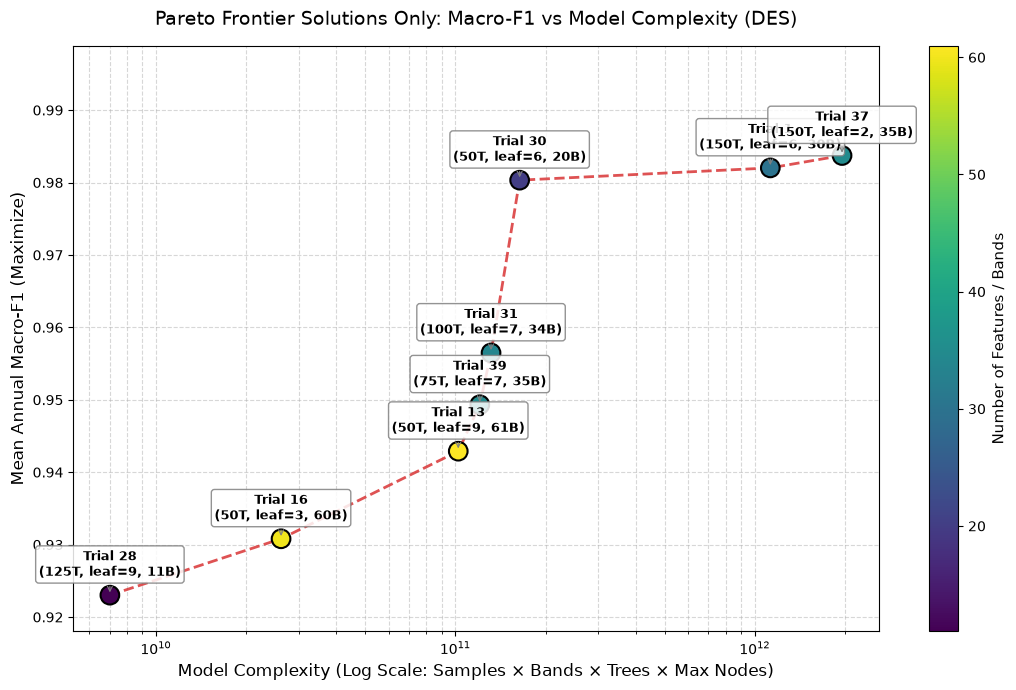


=== Pareto-Optimal Candidates Table for DES ===
 trial_number  macro_f1  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat   sampling
           28  0.923022      7.020514e+09              8788            11    125         9           all stratified
           16  0.930808      2.617945e+10              8788            60     50         3           all stratified
           13  0.942904      1.022556e+11             26378            61     50         9           all stratified
           39  0.949319      1.206892e+11             26378            35     75         7  uncorrelated stratified
           31  0.956474      1.315682e+11             26378            34    100         7           all stratified
           30  0.980329      1.639290e+11             61558            20     50         6           all stratified
            1  0.982023      1.126553e+12             79148            30    150         6           all stratified
           37  0.983733

[I 2026-10-25 14:59:17,719] A new study created in memory with name: rf_IGP



[IGP] Executing Optuna Study...


/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 15:01:26,157] Trial 0 finished with values: [0.9737399391462569, 177105852000.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.9, 'minLeafPopulation': 12, 'numberOfTrees': 50}.
/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 15:04:13,032] Trial 1 finished with values: [0.9618105106683597, 203966802000.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.


[IGP] Generating Pareto Html...


/tmp/ipykernel_13966/1768258234.py:130: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


[IGP] Exporting Trial Data to CSV/JSON...


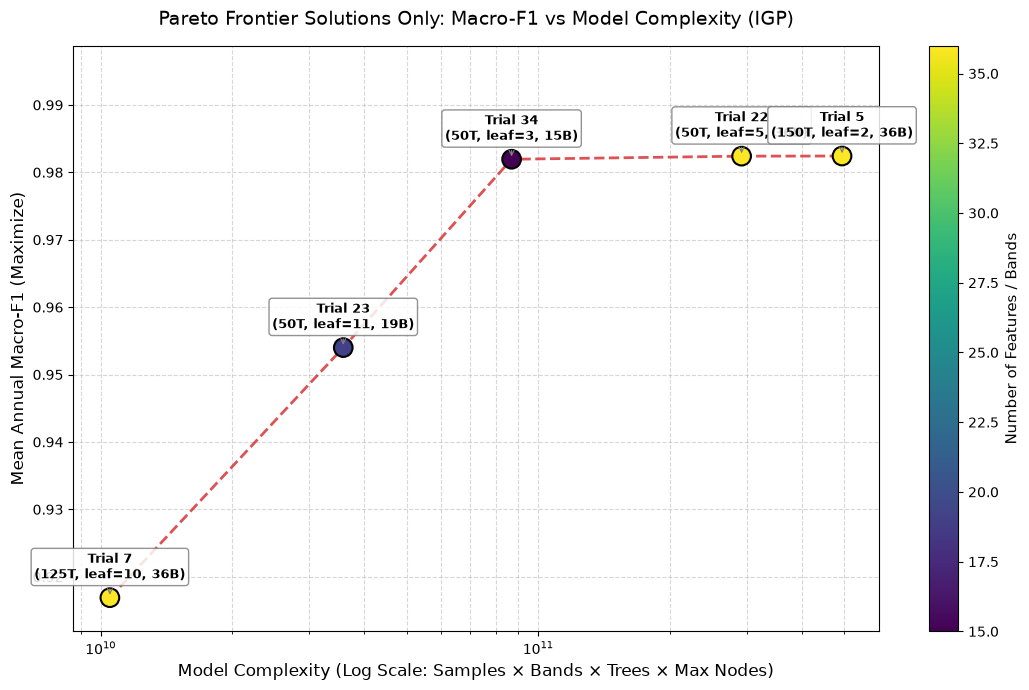


=== Pareto-Optimal Candidates Table for IGP ===
 trial_number  macro_f1  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat           sampling
            7  0.916898      1.049339e+10              5592            36    125        10  uncorrelated         stratified
           23  0.953999      3.583546e+10             30057            19     50        11           all reference_balanced
           34  0.981943      8.689810e+10             39183            15     50         3           all         stratified
           22  0.982402      2.915491e+11             50380            36     50         5  uncorrelated         stratified
            5  0.982422      4.946302e+11             27986            36    150         2  uncorrelated         stratified

[IGP] Pipeline Complete!


🚀 STARTING PIPELINE FOR REGION: WGR

[WGR] Loaded 106 ranked features, 36 uncorrelated features.
[WGR] Loading and caching benchmark years...
1990  Train: 79.81%  Val: 15.33%  Tes

[I 2026-10-25 16:56:31,815] A new study created in memory with name: rf_WGR



[WGR] Executing Optuna Study...


/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 16:56:55,686] Trial 0 finished with values: [0.7884626863285364, 7790829750.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'max_input_features': 90, 'train_fraction': 0.1, 'minLeafPopulation': 10, 'numberOfTrees': 75}.
/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 16:58:21,335] Trial 1 finished with values: [0.9424069140440611, 204135109200.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'uncorrelated', 'train_fracti


[WGR] Generating Pareto Html...


/tmp/ipykernel_13966/1768258234.py:130: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


[WGR] Exporting Trial Data to CSV/JSON...


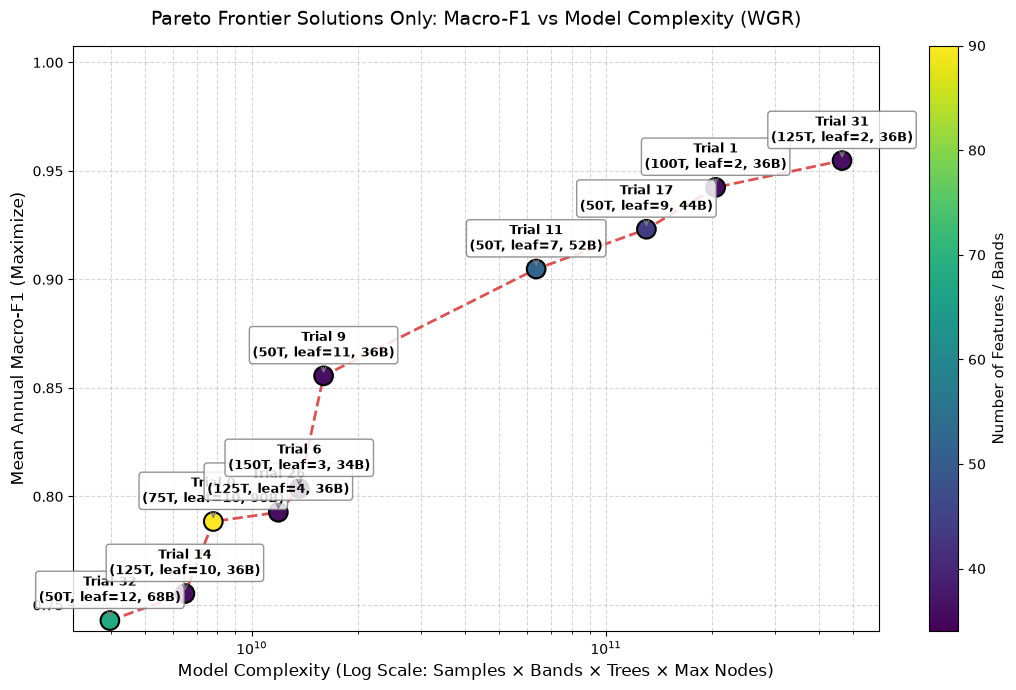


=== Pareto-Optimal Candidates Table for WGR ===
 trial_number  macro_f1  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat           sampling
           32  0.742844      3.978153e+09              3645            68     50        12           all reference_balanced
           14  0.755266      6.478988e+09              3645            36    125        10  uncorrelated reference_balanced
            0  0.788463      7.790830e+09              3641            90     75        10           all         stratified
           26  0.792721      1.189181e+10              3645            36    125         4  uncorrelated reference_balanced
            6  0.803676      1.362610e+10              3645            34    150         3           all reference_balanced
            9  0.855577      1.595999e+10             10933            36     50        11  uncorrelated         stratified
           11  0.904792      6.355026e+10             18227            52     50   

[I 2026-10-25 17:57:34,276] A new study created in memory with name: rf_ICR



[ICR] Executing Optuna Study...


/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 17:57:52,014] Trial 0 finished with values: [0.9470044006200293, 11622134700.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.1, 'minLeafPopulation': 2, 'numberOfTrees': 50}.
/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 17:58:20,340] Trial 1 finished with values: [0.9140276756493524, 14631463000.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.1, 


[ICR] Generating Pareto Html...


/tmp/ipykernel_13966/1768258234.py:130: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


[ICR] Exporting Trial Data to CSV/JSON...


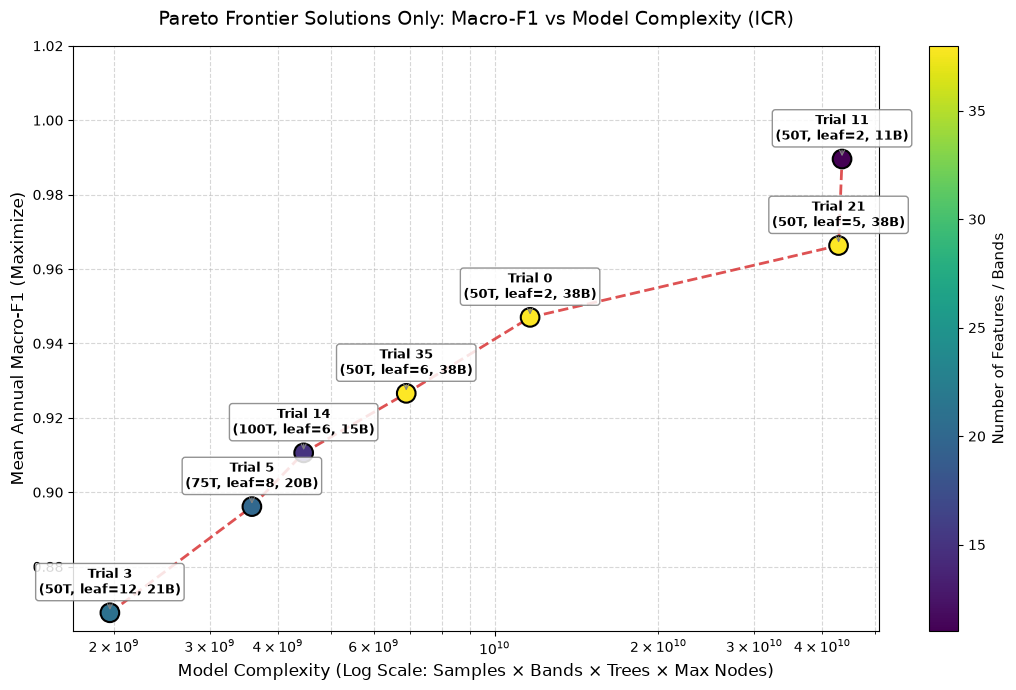


=== Pareto-Optimal Candidates Table for ICR ===
 trial_number  macro_f1  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat           sampling
            3  0.867591      1.965383e+09              5621            21     50        12           all         stratified
            5  0.896133      3.583388e+09              5621            20     75         8           all         stratified
           14  0.910580      4.460264e+09              5621            15    100         6           all         stratified
           35  0.926577      6.883634e+09              5617            38     50         6  uncorrelated reference_balanced
            0  0.947004      1.162213e+10              5617            38     50         2  uncorrelated reference_balanced
           21  0.966312      4.284422e+10             15498            38     50         5  uncorrelated reference_balanced
           11  0.989565      4.348175e+10             32927            11     50   

[I 2026-10-25 19:16:11,719] A new study created in memory with name: rf_NEI



[NEI] Executing Optuna Study...


/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 19:19:22,233] Trial 0 finished with values: [0.9781334644546, 638157020400.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.5, 'minLeafPopulation': 3, 'numberOfTrees': 100}.
/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 19:20:11,154] Trial 1 finished with values: [0.8845235373559553, 26655727500.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.1, '


[NEI] Generating Pareto Html...


/tmp/ipykernel_13966/1768258234.py:130: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


[NEI] Exporting Trial Data to CSV/JSON...


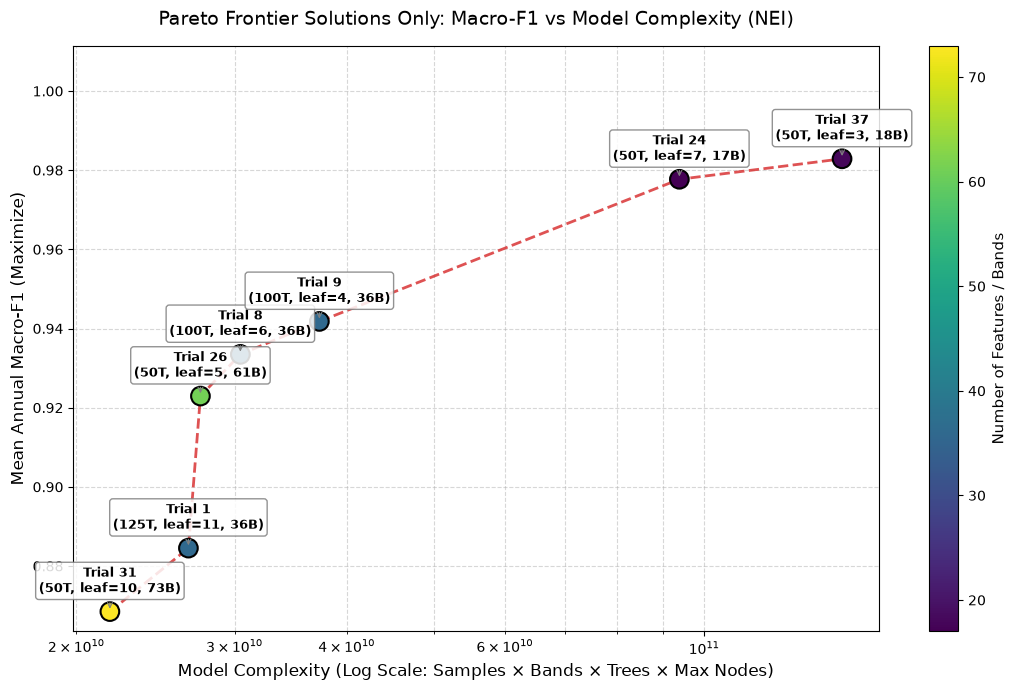


=== Pareto-Optimal Candidates Table for NEI ===
 trial_number  macro_f1  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat           sampling
           31  0.868489      2.179488e+10              7951            73     50        10           all         stratified
            1  0.884524      2.665573e+10              7951            36    125        11  uncorrelated         stratified
           26  0.922940      2.748937e+10              7913            61     50         5           all reference_balanced
            8  0.933470      3.045239e+10              7913            36    100         6  uncorrelated reference_balanced
            9  0.941794      3.728922e+10              7913            36    100         4  uncorrelated reference_balanced
           24  0.977704      9.383815e+10             39783            17     50         7           all         stratified
           37  0.982878      1.423953e+11             39783            18     50   

[I 2026-10-25 21:48:09,502] A new study created in memory with name: rf_PEN



[PEN] Executing Optuna Study...


/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 21:50:24,254] Trial 0 finished with values: [0.8235256615269876, 416855643750.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.9, 'minLeafPopulation': 2, 'numberOfTrees': 125}.
/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 21:51:46,789] Trial 1 finished with values: [0.79300511626979, 185383201500.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fractio


[PEN] Generating Pareto Html...


/tmp/ipykernel_13966/1768258234.py:130: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


[PEN] Exporting Trial Data to CSV/JSON...


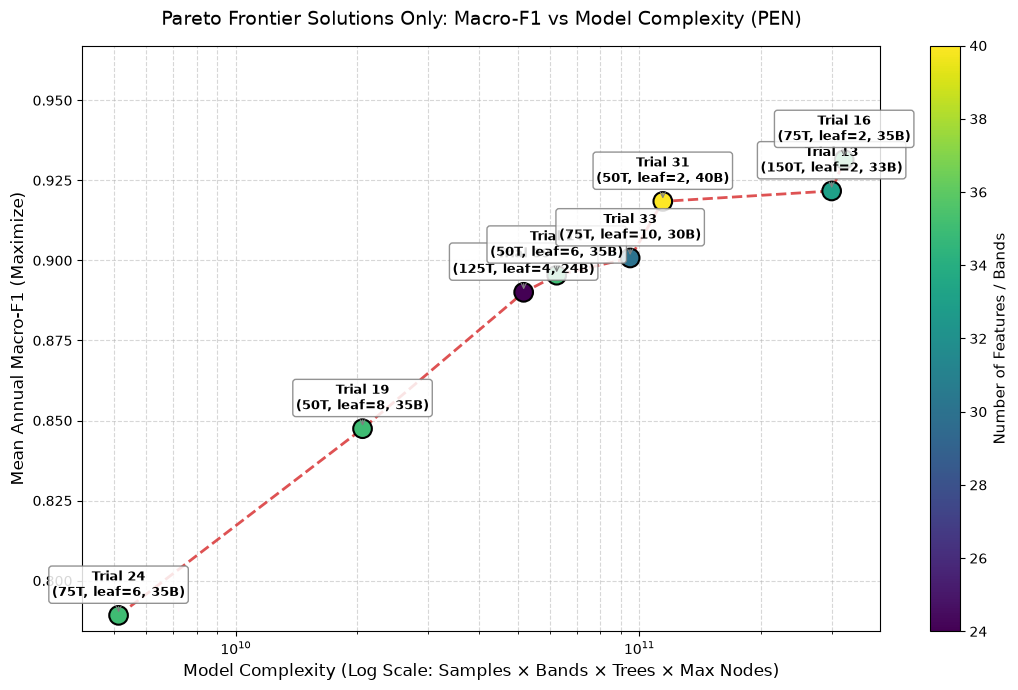


=== Pareto-Optimal Candidates Table for PEN ===
 trial_number  macro_f1  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat   sampling
           24  0.789150      5.119860e+09              3687            35     75         6  uncorrelated stratified
           19  0.847452      2.059855e+10             11073            35     50         8  uncorrelated stratified
           39  0.890041      5.165554e+10             11073            24    125         4           all stratified
           14  0.895381      6.237758e+10             18459            35     50         6  uncorrelated stratified
           33  0.900765      9.484102e+10             25844            30     75        10           all stratified
           31  0.918431      1.142612e+11             18459            40     50         2           all stratified
           13  0.921696      2.994262e+11             18459            33    150         2           all stratified
           16  0.931500

[I 2026-10-25 22:56:53,521] A new study created in memory with name: rf_HIM



[HIM] Executing Optuna Study...


/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 22:57:19,531] Trial 0 finished with values: [0.8660272735306813, 3295647000.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.1, 'minLeafPopulation': 9, 'numberOfTrees': 150}.
/tmp/ipykernel_13966/1768258234.py:55: UserWarning: The distribution is specified by [0.1, 1.0] and step=0.2, but the range is not divisible by `step`. It will be replaced with [0.1, 0.9].
  train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
[I 2026-10-25 22:58:16,763] Trial 1 finished with values: [0.9456236951708012, 24637176000.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.300

In [ ]:
# Cell 2: Master Pipeline (Data Prep -> Optuna -> Plotting -> Export)
for region in TARGET_REGIONS:
    print(f"\n{'='*70}")
    print(f"🚀 STARTING PIPELINE FOR REGION: {region}")
    print(f"{'='*70}\n")
    # --- STEP 1: Load Features ---
    with open(artifact_dir / f"{region}_ranked_features.json", "r") as f:
        all_ranked = json.load(f)["ranked_features"]
    with open(artifact_dir / f"{region}_uncorrelated_features.json", "r") as f:
        uncorr_ranked = json.load(f)["uncorrelated_features"]
    
    print(f"[{region}] Loaded {len(all_ranked)} ranked features, {len(uncorr_ranked)} uncorrelated features.")

    # --- STEP 2: Pre-Partition Data ---
    print(f"[{region}] Loading and caching benchmark years...")
    region_dir = data_base_dir / region
    cache_dir = Path(f'data/cache_splits_{region}')
    
    if cache_dir.exists():
        shutil.rmtree(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    
    for yr in BENCHMARK_YEARS:
        sp = load_year_split(region, yr, all_ranked, gated=True)
        X_train, y_train = sp['train']
        X_val, y_val = sp['val']
        X_test, y_test = sp['test']

        total_samples = len(X_train) + len(X_val) + len(X_test)
        print(f"{yr}  Train: {len(X_train)/total_samples:.2%}  "
              f"Val: {len(X_val)/total_samples:.2%}  Test: {len(X_test)/total_samples:.2%}")

        np.savez_compressed(cache_dir / f"split_{yr}.npz", X_tr=X_train, y_tr=y_train,
                            X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)
        del X_train, y_train, X_val, y_val, X_test, y_test, sp
        gc.collect()

    # --- STEP 3: Optuna Optimization ---
    print(f"\n[{region}] Executing Optuna Study...")
    feat_to_idx = {name: i for i, name in enumerate(all_ranked)}
    ref_col_series = parent_ref_df[region] if region in parent_ref_df.columns else None

    def objective(trial):
        sampling_strategy = trial.suggest_categorical("sampling_strategy", ["stratified", "reference_balanced"])
        feat_strategy = trial.suggest_categorical("feature_strategy", ["all", "uncorrelated"])
        
        if feat_strategy == "uncorrelated":
            active_names = uncorr_ranked
        else:
            num_bands = trial.suggest_int("max_input_features", 10, len(all_ranked))
            active_names = all_ranked[:num_bands]
            
        active_col_idx = [feat_to_idx[f] for f in active_names]
        train_fraction = trial.suggest_float("train_fraction", 0.10, 1.0, step=0.20)
        min_leaf = trial.suggest_int("minLeafPopulation", 2, 12)
        n_trees = trial.suggest_int("numberOfTrees", 50, 150, step=25)

        rf_params = {
            "n_estimators": n_trees, "min_samples_leaf": min_leaf,
            "max_features": "sqrt", "max_depth": None,
            "n_jobs": 2, "random_state": 42
        }

        yearly_macro_f1s = []
        annual_training_sample_counts = []
        all_year_max_nodes = []
        rng = np.random.RandomState(42)

        for yr in BENCHMARK_YEARS:
            data = np.load(cache_dir / f"split_{yr}.npz")
            X_tr, y_tr, X_val, y_val = data['X_tr'], data['y_tr'], data['X_val'][:, active_col_idx], data['y_val']
            target_n = int(len(X_tr) * train_fraction)

            if train_fraction >= 0.99 and sampling_strategy == "stratified":
                chosen_local = np.arange(len(X_tr))
            elif sampling_strategy == "reference_balanced" and ref_col_series is not None:
                chosen_local = get_balanced_indices(y_tr, target_n, ref_col_series, rng)
            else:
                chosen_local = []
                for cls in np.unique(y_tr):
                    cls_indices = np.where(y_tr == cls)[0]
                    n_take = max(3, int(target_n * len(cls_indices) / len(y_tr)))
                    chosen_local.extend(rng.choice(cls_indices, size=min(len(cls_indices), n_take), replace=False))
                chosen_local = np.array(chosen_local)

            annual_training_sample_counts.append(len(chosen_local))
            X_sub, y_sub = X_tr[chosen_local][:, active_col_idx], y_tr[chosen_local]

            clf = RandomForestClassifier(**rf_params)
            clf.fit(X_sub, y_sub)

            all_year_max_nodes.append(max(tree.tree_.node_count for tree in clf.estimators_))
            yearly_macro_f1s.append(f1_score(y_val, clf.predict(X_val), average="macro"))

            del data, X_tr, y_tr, X_val, y_val, X_sub, y_sub, clf
            gc.collect()

        mean_macro_f1 = float(np.mean(yearly_macro_f1s))
        samples_per_year = int(np.mean(annual_training_sample_counts))
        max_nodes_observed = int(max(all_year_max_nodes))
        num_features = len(active_col_idx)
        single_model_complexity = float(samples_per_year * num_features * n_trees * max_nodes_observed)

        trial.set_user_attr("samples_per_year", samples_per_year)
        trial.set_user_attr("num_features", num_features)
        trial.set_user_attr("max_nodes", max_nodes_observed)
        trial.set_user_attr("model_complexity", single_model_complexity)

        return mean_macro_f1, single_model_complexity

    # Standard in-memory study
    study = optuna.create_study(
        study_name=f"rf_{region}", 
        directions=["maximize", "minimize"]
    )
    study.optimize(objective, n_trials=40, n_jobs=1)

    # --- STEP 4: Plotly Visualization ---
    print(f"\n[{region}] Generating Pareto Html...")
    fig_plotly = plot_pareto_front(study, target_names=["Mean Macro-F1", "Model Complexity"])
    fig_plotly.update_layout(title=f"Multi-Objective Pareto Front (F1 vs Model Complexity) - {region}", width=900, height=550)
    fig_plotly.write_html(output_config_dir / f"{region}_pareto_frontier.html")
    fig_plotly.show()

    # --- STEP 5: Data Export ---
    print(f"[{region}] Exporting Trial Data to CSV/JSON...")
    df_all_trials = study.trials_dataframe()
    df_all_trials.to_csv(output_config_dir / f"{region}_all_trials.csv", index=False)
    df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)

    # --- STEP 6: Matplotlib Custom Pareto Analysis ---
    pareto_records = []
    for t in study.best_trials:
        strat = t.params.get("feature_strategy", "all")
        n_feats = len(uncorr_ranked) if strat == "uncorrelated" else t.params.get("max_input_features", len(all_ranked))
            
        pareto_records.append({
            "trial_number": t.number,
            "macro_f1": float(t.values[0]),
            "model_complexity": float(t.values[1]),
            "samples_per_year": t.user_attrs.get("samples_per_year"),
            "num_features": t.user_attrs.get("num_features", n_feats),
            "max_nodes": t.user_attrs.get("max_nodes"),
            "trees": t.params.get("numberOfTrees"),
            "min_leaf": t.params.get("minLeafPopulation"),
            "sampling": t.params.get("sampling_strategy"),
            "feature_strat": strat,
            "train_fraction": t.params.get("train_fraction")
        })

    if pareto_records:
        df_pareto = pd.DataFrame(pareto_records).sort_values("model_complexity")
        df_pareto.to_csv(output_config_dir / f"{region}_pareto_frontier.csv", index=False)
        df_pareto.to_json(output_config_dir / f"{region}_pareto_frontier.json", orient="records", indent=4)

        fig, ax = plt.subplots(figsize=(11, 7))
        ax.plot(df_pareto["model_complexity"], df_pareto["macro_f1"], color="#d62728", linestyle="--", linewidth=2, alpha=0.8, zorder=2, label="Pareto Efficient Frontier")
        scatter = ax.scatter(df_pareto["model_complexity"], df_pareto["macro_f1"], c=df_pareto["num_features"], cmap="viridis", s=180, edgecolor="black", linewidth=1.5, zorder=3)
        
        cbar = plt.colorbar(scatter, ax=ax)
        cbar.set_label("Number of Features / Bands", fontsize=11)

        for _, row in df_pareto.iterrows():
            label_text = f"Trial {int(row['trial_number'])}\n({int(row['trees'])}T, leaf={int(row['min_leaf'])}, {int(row['num_features'])}B)"
            ax.annotate(
                label_text, xy=(row["model_complexity"], row["macro_f1"]), xytext=(0, 14), textcoords="offset points",
                ha="center", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="gray", alpha=0.85),
                arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0", color="gray", lw=0.8)
            )

        ax.set_xscale("log")
        ax.set_title(f"Pareto Frontier Solutions Only: Macro-F1 vs Model Complexity ({region})", fontsize=14, pad=15)
        ax.set_xlabel("Model Complexity (Log Scale: Samples × Bands × Trees × Max Nodes)", fontsize=12)
        ax.set_ylabel("Mean Annual Macro-F1 (Maximize)", fontsize=12)
        ax.grid(True, which="both", linestyle="--", alpha=0.5)

        y_margin = (df_pareto["macro_f1"].max() - df_pareto["macro_f1"].min()) * 0.25
        ax.set_ylim(df_pareto["macro_f1"].min() - 0.005, df_pareto["macro_f1"].max() + y_margin)

        plt.tight_layout()
        plt.savefig(output_config_dir / f"{region}_pareto_only_frontier.png", dpi=300, bbox_inches="tight")
        plt.show()

        print(f"\n=== Pareto-Optimal Candidates Table for {region} ===")
        display_cols = ["trial_number", "macro_f1", "model_complexity", "samples_per_year", "num_features", "trees", "min_leaf", "feature_strat", "sampling"]
        print(df_pareto[display_cols].to_string(index=False))

    print(f"\n[{region}] Pipeline Complete!\n")
    gc.collect()